# Week 3 — Unsupervised Learning & Model Evaluation

**YuvaIntern | AI Pioneers Internship | Sahil Sant**

This notebook accompanies the report and runs the reproducible analysis in `src/run_analysis.py`. It uses the Scikit-learn Breast Cancer Wisconsin Diagnostic benchmark dataset. The dataset is for education only and is **not intended for diagnosis or clinical decisions**.

The project separates two workflows:
1. **Unsupervised:** K-Means, hierarchical clustering, silhouette score, post-hoc ARI, and PCA.
2. **Supervised evaluation:** stratified train/test split, five-fold cross-validation, GridSearchCV, confusion matrices, precision, recall, F1, and ROC-AUC.

Diagnosis labels are excluded from the clustering input. They are used only for post-hoc cluster comparison and separately as the target in the supervised task.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

# Find the project root whether the notebook is started from the repo root or notebooks/.
candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(p for p in candidates if (p / 'src' / 'run_analysis.py').exists())
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

print('Project root:', PROJECT_ROOT)
print('Existing dataset:', (PROJECT_ROOT / 'data' / 'breast_cancer.csv').exists())

Project root: /mnt/data/yuva-intern-week3-unsupervised-evaluation
Existing dataset: True


## 1. Load and inspect the data

The dataset has 569 observations and 30 numeric predictors. The target column is `diagnosis_malignant`: `1` means malignant and `0` means benign. We keep the target separate from the feature matrix when clustering.

In [2]:
from run_analysis import prepare_dataset

df = prepare_dataset()
X = df.drop(columns=['diagnosis_malignant'])
y = df['diagnosis_malignant']
print('Rows, columns:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Diagnosis counts (0=benign, 1=malignant):')
display(y.value_counts().sort_index().rename(index={0: 'Benign (0)', 1: 'Malignant (1)'}).to_frame('observations'))
display(df.head())

Rows, columns: (569, 31)
Missing values: 0
Diagnosis counts (0=benign, 1=malignant):


,observations
diagnosis_malignant,
Benign (0),357
Malignant (1),212


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis_malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 2. Run clustering and PCA

Standardization is used because distance-based algorithms can otherwise be dominated by features with larger numeric scales. K-Means and Agglomerative Clustering are compared for `k = 2, 3, 4, 5, 6`. The silhouette score is used to choose the displayed cluster count. ARI is calculated **after fitting only** as an external comparison; it is not fed into clustering or used to select `k`. PCA is for projection/visualization, while clustering runs in all 30 standardized features.

In [3]:
from run_analysis import run_clustering

cluster_results = run_clustering(df)
clustering_table = pd.read_csv(PROJECT_ROOT / 'results' / 'clustering_metrics.csv')
display(clustering_table.round(4))
print('Best K-Means k by silhouette:', cluster_results['best_kmeans_k'])
print('Best K-Means silhouette:', round(cluster_results['best_kmeans_silhouette'], 4))
print('PCA variance retained by first two components:', round(cluster_results['pca_cumulative'] * 100, 2), '%')

,algorithm,n_clusters,silhouette_score,adjusted_rand_index_vs_diagnosis,inertia
0,K-Means,2,0.3450,0.6707,11595.4615
1,Agglomerative (Hierarchical),2,0.3394,0.5750,NaN
2,K-Means,3,0.3144,0.5107,10061.7978
3,Agglomerative (Hierarchical),3,0.3301,0.5363,NaN
4,K-Means,4,0.2803,0.5549,9257.3625
5,Agglomerative (Hierarchical),4,0.2982,0.5434,NaN
6,K-Means,5,0.1585,0.3316,8557.7275
7,Agglomerative (Hierarchical),5,0.2434,0.5038,NaN
8,K-Means,6,0.1604,0.3322,7970.2638
9,Agglomerative (Hierarchical),6,0.1199,0.2865,NaN


Best K-Means k by silhouette: 2
Best K-Means silhouette: 0.345
PCA variance retained by first two components: 63.24 %


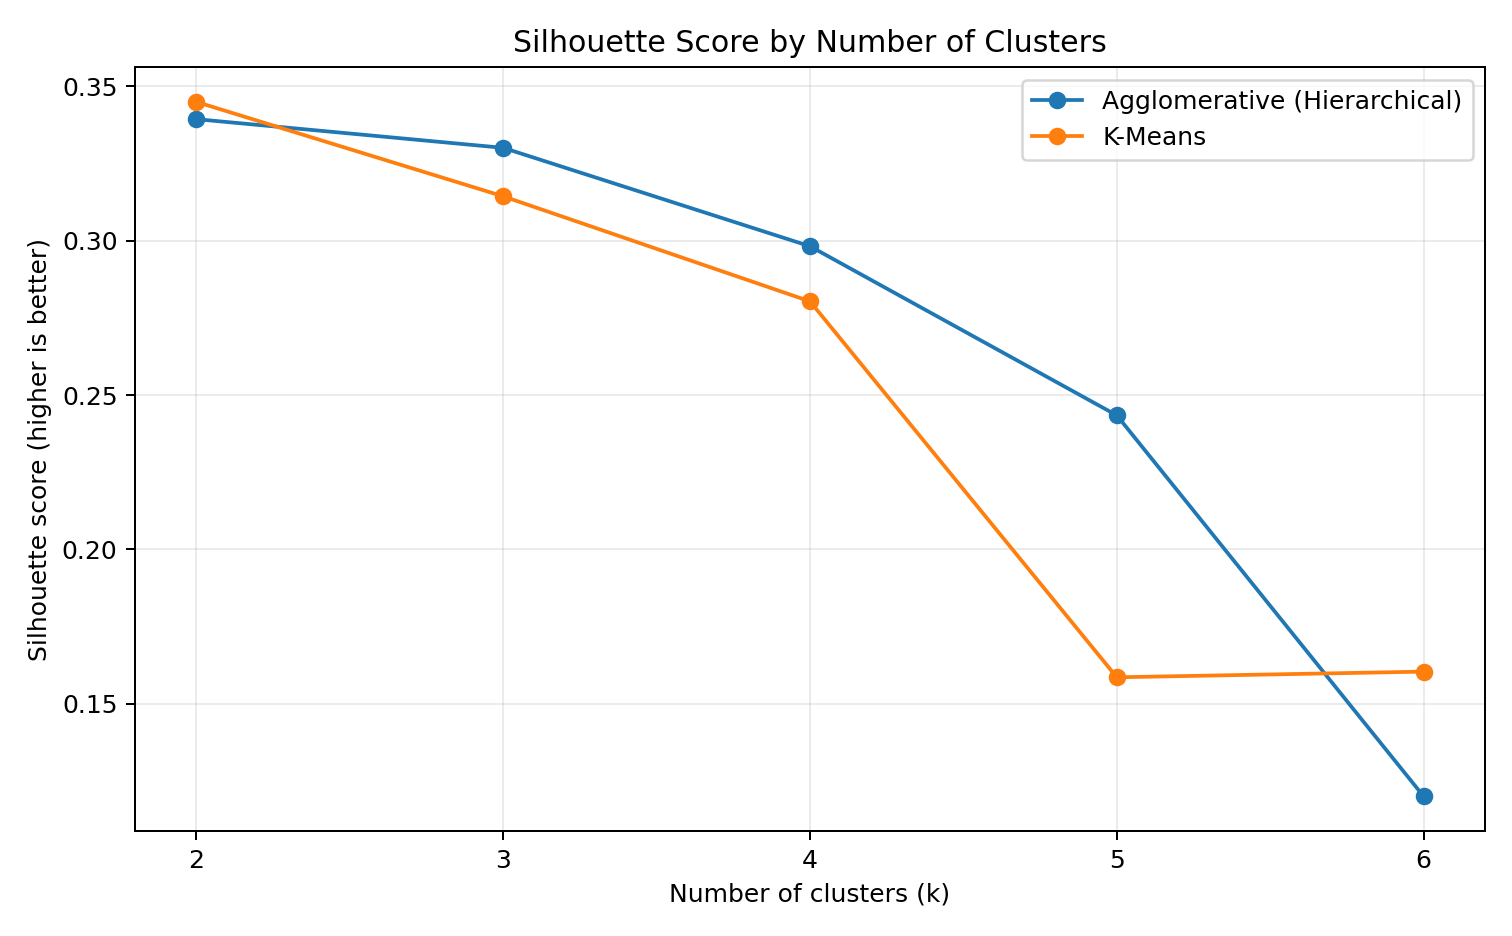

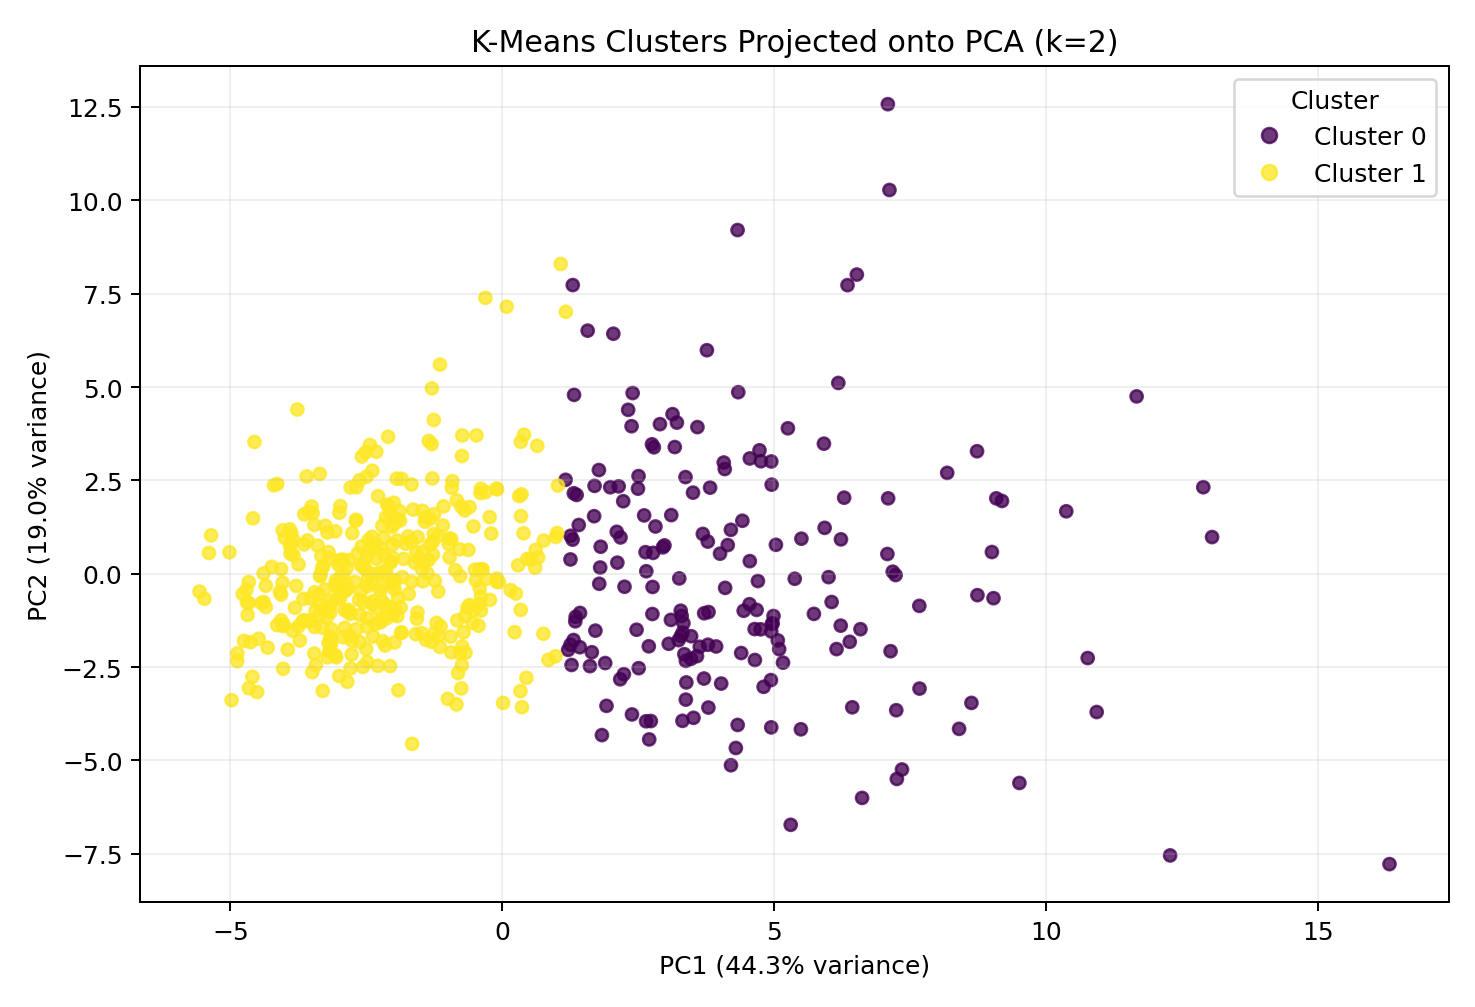

,cluster,observations,malignant_fraction_posthoc,mean_radius,mean_texture,mean_perimeter
0,0,189,0.926,17.557,21.359,116.408
1,1,380,0.097,12.422,18.260,79.814


In [4]:
from IPython.display import Image, display as show_image

show_image(Image(filename=str(PROJECT_ROOT / 'figures' / 'clustering_silhouette_by_k.png')))
show_image(Image(filename=str(PROJECT_ROOT / 'figures' / 'kmeans_clusters_pca_projection.png')))
display(pd.read_csv(PROJECT_ROOT / 'results' / 'cluster_profile.csv').round(3))

## 3. Supervised model evaluation

The supervised workflow is separate from clustering. A stratified 80/20 split is used. Both Logistic Regression and Random Forest are tuned on the training split using five-fold `StratifiedKFold` cross-validation and `GridSearchCV`, optimizing ROC-AUC. The held-out test set is kept for final metrics only.

In [5]:
from run_analysis import run_supervised

supervised_results = run_supervised(df)
model_table = pd.read_csv(PROJECT_ROOT / 'results' / 'supervised_model_metrics.csv')
cols = ['model', 'test_accuracy', 'test_precision_malignant', 'test_recall_malignant',
        'test_f1_malignant', 'test_roc_auc', 'cv_best_mean_roc_auc', 'best_params']
display(model_table[cols].round(4))
print('Training shape:', supervised_results['X_train_shape'])
print('Test shape:', supervised_results['X_test_shape'])

,model,test_accuracy,test_precision_malignant,test_recall_malignant,test_f1_malignant,test_roc_auc,cv_best_mean_roc_auc,best_params
0,Logistic Regression,0.9649,0.975,0.9286,0.9512,0.996,0.9958,"{""model__C"": 1.0, ""model__class_weight"": null}"
1,Random Forest,0.9649,1.000,0.9048,0.9500,0.994,0.9891,"{""model__max_depth"": 8, ""model__min_samples_le..."


Training shape: (455, 30)
Test shape: (114, 30)


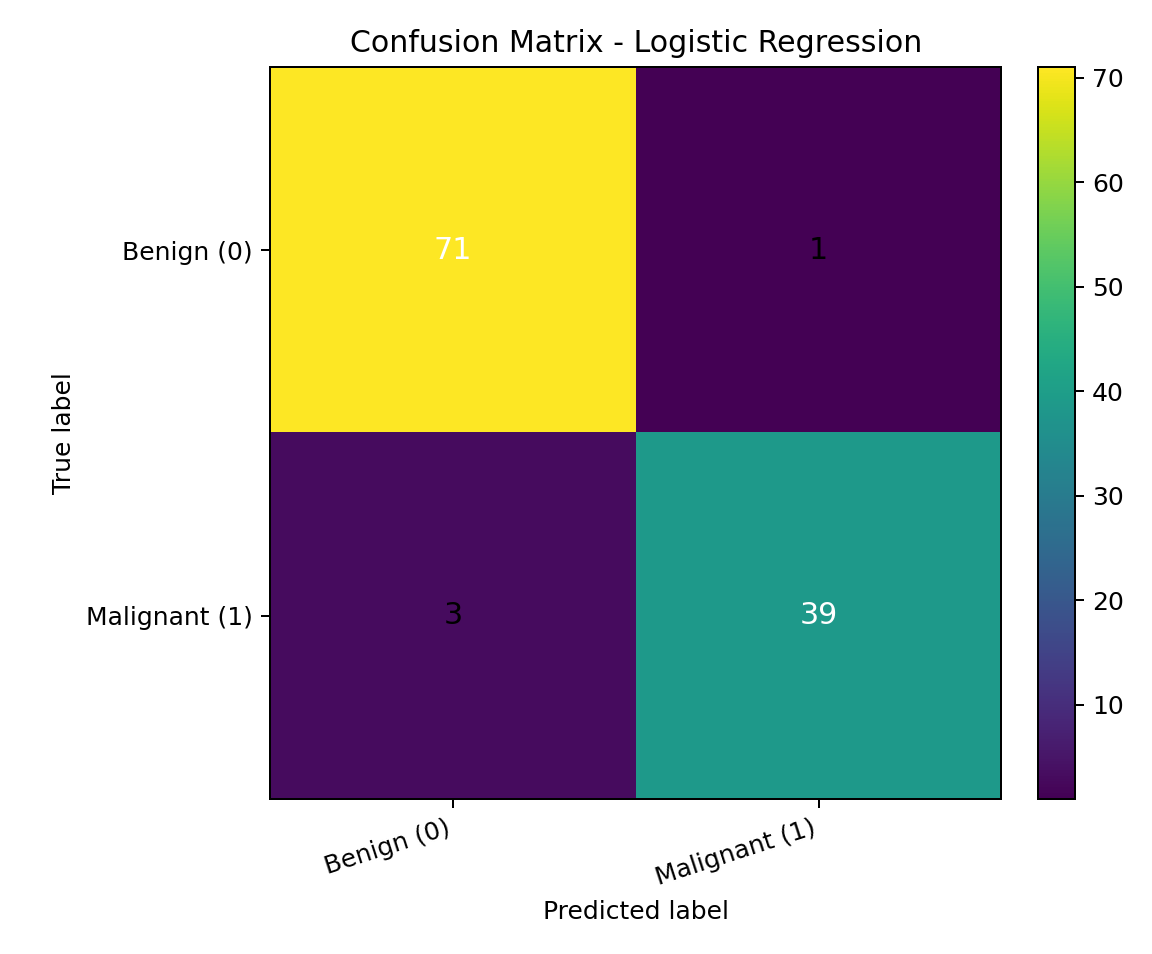

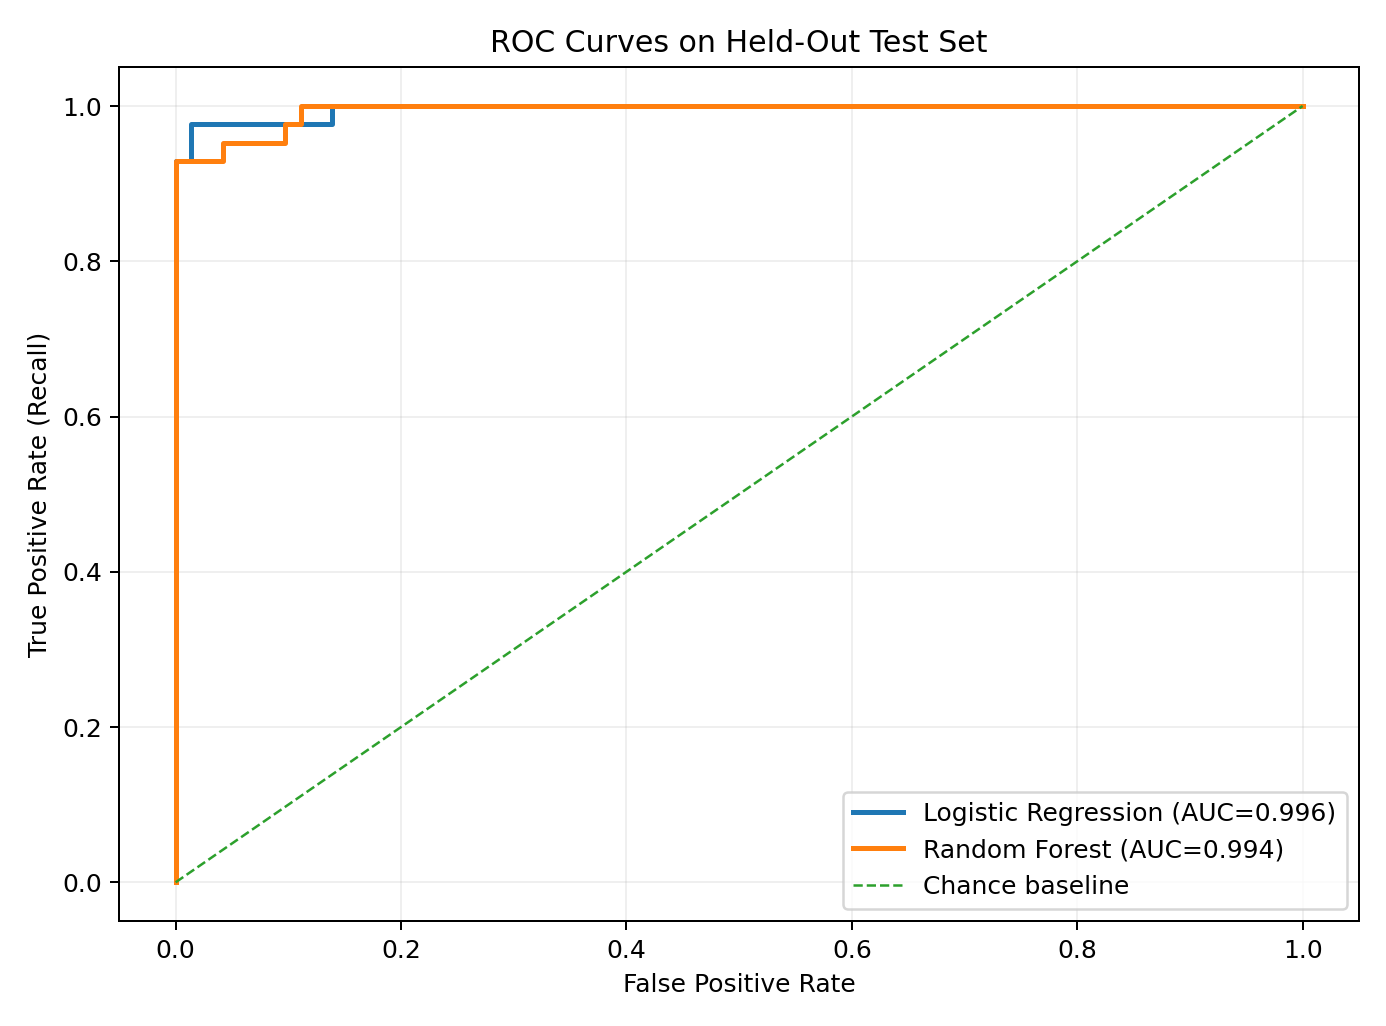

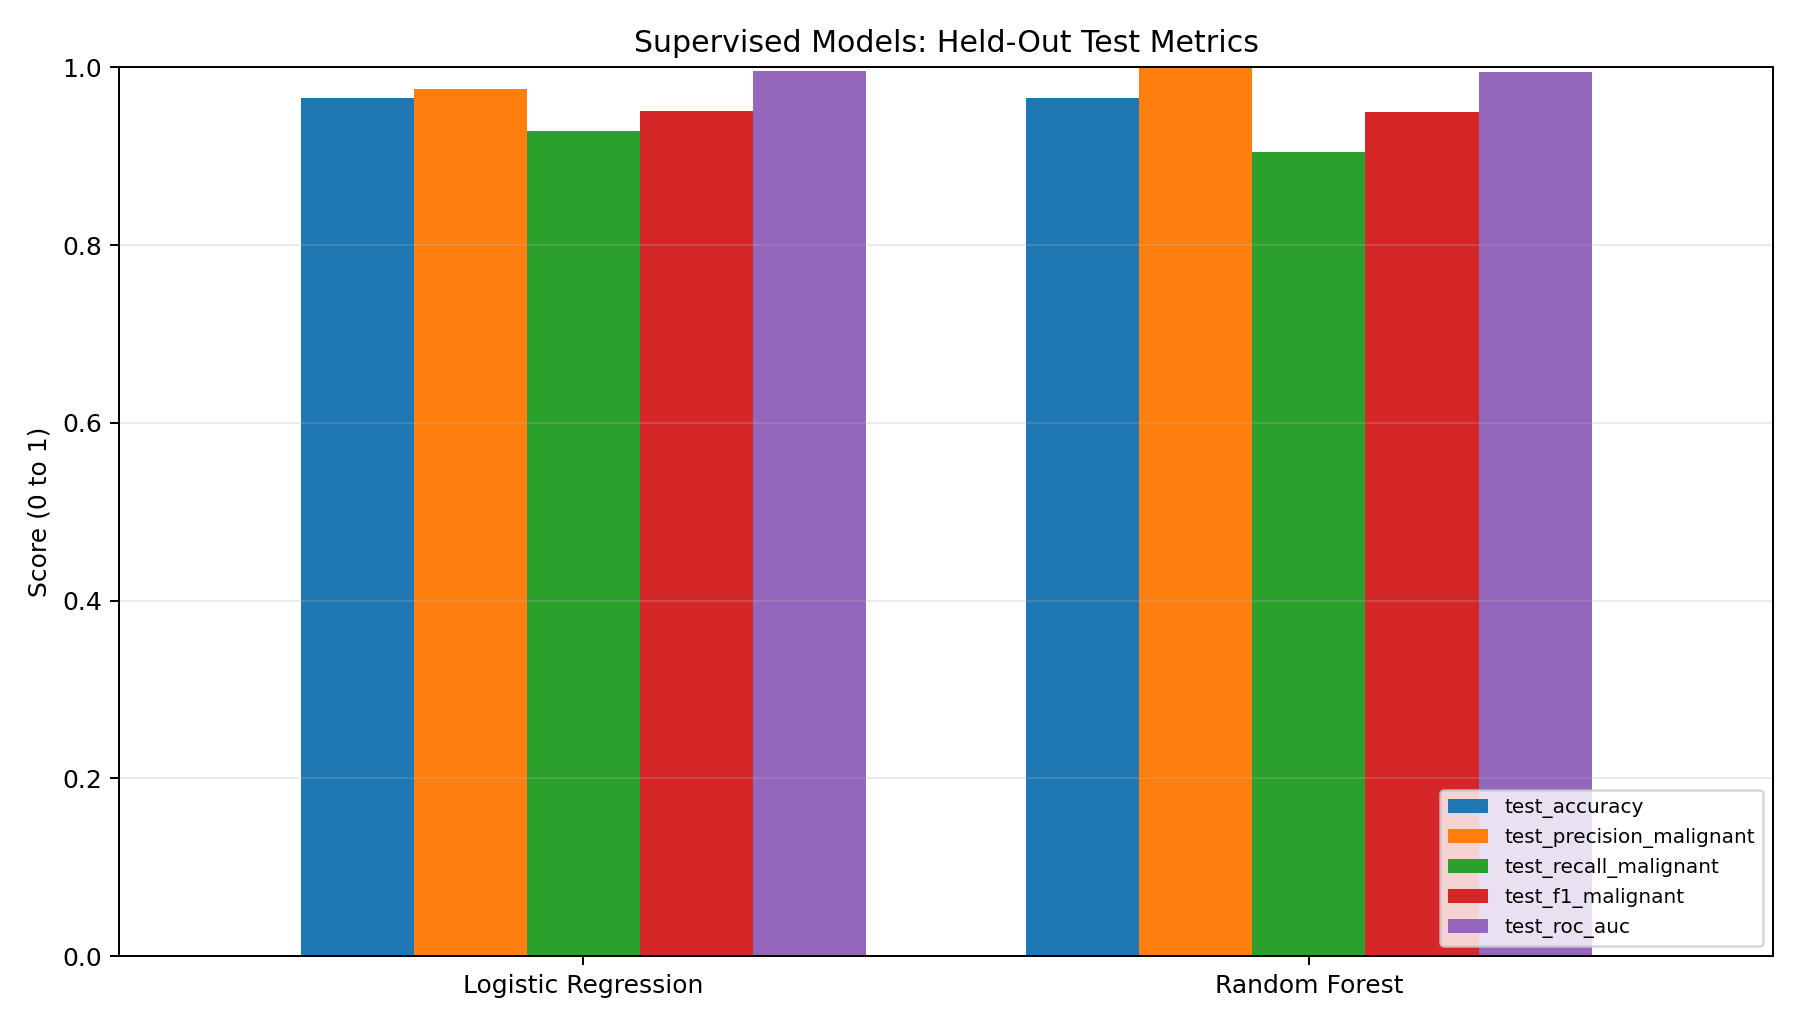

,model,fold,validation_roc_auc
0,Logistic Regression,1,0.9948
1,Logistic Regression,2,0.9990
2,Logistic Regression,3,1.0000
3,Logistic Regression,4,0.9871
4,Logistic Regression,5,0.9979
5,Random Forest,1,0.9835
6,Random Forest,2,1.0000
7,Random Forest,3,0.9938
8,Random Forest,4,0.9856
9,Random Forest,5,0.9827


In [6]:
show_image(Image(filename=str(PROJECT_ROOT / 'figures' / 'best_model_confusion_matrix.png')))
show_image(Image(filename=str(PROJECT_ROOT / 'figures' / 'roc_curve_comparison.png')))
show_image(Image(filename=str(PROJECT_ROOT / 'figures' / 'supervised_model_metrics.png')))
display(pd.read_csv(PROJECT_ROOT / 'results' / 'best_models_cv_fold_scores.csv').round(4))

## 4. Interpretation and limitations

The experiment should be interpreted through multiple metrics rather than accuracy alone. Precision describes the correctness of positive (malignant) predictions; recall describes the proportion of malignant test cases detected; F1 balances precision and recall; ROC-AUC measures ranking/discrimination across thresholds. The clustering labels are arbitrary IDs, and the PCA figure is only a 2D view of the original 30-dimensional clusters.

This is a small educational benchmark, not a clinical tool. The reported test results apply to this one reproducible split and parameter search. Do not use this model for real medical decisions.

In [7]:
print('Summary file:')
display(pd.Series(__import__('json').loads((PROJECT_ROOT / 'results' / 'run_summary.json').read_text()), name='value').to_frame())

Summary file:


,value
dataset,Scikit-learn Breast Cancer Wisconsin Diagnosti...
rows,569
predictor_count,30
benign_count,357
malignant_count,212
clustering_best_kmeans_k_by_silhouette,2
clustering_best_kmeans_silhouette,0.344974
clustering_best_kmeans_ari_posthoc,0.670721
pca_pc1_variance_ratio,0.44272
pca_pc2_variance_ratio,0.189712
